In [168]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import datetime
import cvxpy as cp

In [169]:
import time
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

from kneed import KneeLocator

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objs as go
import plotly
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot
import cufflinks as cf
cf.set_config_file(offline=True)


In [170]:
import seaborn as sns
import warnings
import os

from tslearn.clustering import TimeSeriesKMeans
from tslearn.barycenters import dtw_barycenter_averaging

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE, MDS
from sklearn.cluster import AgglomerativeClustering

from scipy.cluster.hierarchy import dendrogram
from tqdm.autonotebook import tqdm

warnings.filterwarnings("ignore")
sns.set_style("darkgrid")

In [171]:
df_network = pd.read_excel('Networkdata.xlsx')
df_community = pd.read_excel('community_rural.xlsx')

In [172]:
df_community

,Date_Hour_start,b1,b2,b3,b4,b5,b6,b7,b8,b9,b10
0,2019-01-01 00:00:00,9.780,14.698,7,13.828,20.277,7.467,19.588,8.295,4.319,6.0
1,2019-01-01 01:00:00,12.408,10.672,6,13.376,17.127,6.576,16.876,11.388,6.452,4.5
2,2019-01-01 02:00:00,8.044,7.426,7,10.952,12.719,6.695,11.448,10.752,7.021,6.0
3,2019-01-01 03:00:00,8.362,6.542,7,5.522,8.057,5.004,10.723,5.976,5.062,6.0
4,2019-01-01 04:00:00,9.532,8.716,7,7.390,10.193,3.634,13.482,8.370,6.648,6.0
...,...,...,...,...,...,...,...,...,...,...,...
8755,2019-12-31 19:00:00,9.984,1.736,13,3.748,2.212,13.404,6.728,21.867,10.791,58.5
8756,2019-12-31 20:00:00,9.918,1.586,11,2.399,1.591,12.651,6.545,11.790,6.297,55.5
8757,2019-12-31 21:00:00,9.934,1.576,11,2.173,1.057,8.558,6.543,12.504,6.743,42.0
8758,2019-12-31 22:00:00,11.994,1.866,11,7.614,6.027,7.343,7.863,16.629,9.268,19.5


Here are main functions we'll use in this notebook, which help us find optimal cluster numbers and produce the dataframe with cluster labels.

To find the optimal cluster number, there are three basic steps:

Normalize all variables in the dataframe 
Calculate inertia for each cluster number in the search range we set
Draw the curve between inertia in y-axis and cluster number in x-axis, and find the optimal cluster number via elbow method

In [173]:
def MinMaxScaler(data):
    return (data-np.min(data))/(np.max(data)-np.min(data))

def Kmeans_clustering(df, clusterNum, max_iter=1000, n_jobs=-1):
    '''
    Function for doing kmeans clustering.
    Inputs should include at least the dataframe of variables and cluster number you want.
    '''
    # Normalize the dataframe
    scaler = StandardScaler()
    scaler.fit(df) 
    df_std = pd.DataFrame(data=scaler.transform(df), columns=df.columns, index=df.index)
    
    # Kmeans clustering
    km_model = KMeans(n_clusters=clusterNum, max_iter=max_iter, random_state=666)
    km_model = km_model.fit(df_std)
    
    clusterdf= pd.DataFrame(data=km_model.labels_, columns=['ClusterNo'])
    clusterdf.index = df.index
    
    return clusterdf

def Kmeans_bestClusterNum(df, range_min, range_max, max_iter=1000, n_jobs=-1):
    '''
    Function for finding optimal number of kmeans clustering.
    Inputs should include at least the dataframe of variables, and search range of cluster number (min & max cluster number).
    '''    
    
    # Normalize the dataframe
    scaler = StandardScaler()
    scaler.fit(df) 
    df_std = pd.DataFrame(data=scaler.transform(df), columns=df.columns, index=df.index)       
    
    # Calculate inertia for each cluster number in the research range
    sum_of_squared_distances = [] #Inertia of all clustering results
    ks = range(range_min,range_max+1)
    for k in ks:
        kmeans_fit = KMeans(n_clusters = k, max_iter=max_iter, random_state=666).fit(df_std)
        cluster_labels = kmeans_fit.labels_
        sum_of_squared_distances.append(kmeans_fit.inertia_)
        
    # Use kneed package to locate the elbow / knee of the curve line
    kn = KneeLocator(list(ks), sum_of_squared_distances, S=1.0, curve='convex', direction='decreasing')  
    
    # Plot the result of finding optimal cluster number
    plt.xlabel('k')
    plt.ylabel('sum_of_squared_distances')
    plt.title('The Elbow Method showing the optimal k')
    plt.plot(ks, sum_of_squared_distances, 'bx-')
    plt.vlines(kn.knee, plt.ylim()[0], plt.ylim()[1], linestyles='dashed')
    plt.show()
    
    print('Optimal clustering number:'+str(kn.knee))
    print('----------------------------')    
    
    return kn.knee

## Clustering the load of each node
### b5

In [174]:
df_community['Date_Hour_start'] = pd.to_datetime(df_community['Date_Hour_start'])

In [175]:
df_community.set_index('Date_Hour_start')

,b1,b2,b3,b4,b5,b6,b7,b8,b9,b10
Date_Hour_start,,,,,,,,,,
2019-01-01 00:00:00,9.780,14.698,7,13.828,20.277,7.467,19.588,8.295,4.319,6.0
2019-01-01 01:00:00,12.408,10.672,6,13.376,17.127,6.576,16.876,11.388,6.452,4.5
2019-01-01 02:00:00,8.044,7.426,7,10.952,12.719,6.695,11.448,10.752,7.021,6.0
2019-01-01 03:00:00,8.362,6.542,7,5.522,8.057,5.004,10.723,5.976,5.062,6.0
2019-01-01 04:00:00,9.532,8.716,7,7.390,10.193,3.634,13.482,8.370,6.648,6.0
...,...,...,...,...,...,...,...,...,...,...
2019-12-31 19:00:00,9.984,1.736,13,3.748,2.212,13.404,6.728,21.867,10.791,58.5
2019-12-31 20:00:00,9.918,1.586,11,2.399,1.591,12.651,6.545,11.790,6.297,55.5
2019-12-31 21:00:00,9.934,1.576,11,2.173,1.057,8.558,6.543,12.504,6.743,42.0


In [176]:
#df_community['Sum'] = df_community.loc[:,'b5':'b3'].sum(axis=1)

In [177]:
df_community['b1'].iplot()

In [178]:
df_b1 = pd.DataFrame({'Date_Hour_start': df_community['Date_Hour_start'],
        'load':  df_community['b1']})
df_b1['date'] = df_b1['Date_Hour_start'].dt.date    
df_b1['hour'] = df_b1['Date_Hour_start'].dt.hour
df_b1_pivot = df_b1.pivot_table(index='hour', columns='date')

In [179]:
df_b1_pivot

load                                                         \
date 2019-01-01 2019-01-02 2019-01-03 2019-01-04 2019-01-05 2019-01-06   
hour                                                                     
0         9.780      7.448     10.904     12.876      7.730      9.428   
1        12.408     10.594     10.140      6.942      8.980     13.742   
2         8.044      9.340     11.420     11.116      5.860      7.402   
3         8.362     10.254     13.874      9.334     11.520     11.400   
4         9.532     11.516     10.308     13.572      6.304      6.448   
5         4.690      8.654      9.450      9.628      8.906     10.722   
6        12.014     11.696     13.194     12.564      9.904      7.824   
7         4.828     10.822     17.014     13.292      8.206      8.118   
8        12.864     10.418     14.302     13.194     14.488     10.026   
9         5.450     11.390      9.322      6.146      5.720      9.130   
10        7.548     11.532     12.370     10.260     11.006     11.244   
11        9.792     11.508     15.474      5.274      5.556     11.234   
12        9.842     13.190     10.232     13.844     10.126      7.298   
13       13.744     12.800     12.694      9.020      8.454      9.418   
14       10.582     13.694      9.268      9.650      8.412      7.830   
15        9.086     11.874     15.866      7.806     10.326      7.468   
16       10.404     16.620      8.492      5.872     10.052     11.166   
17        7.980     11.534     13.984     11.002     10.992      5.102   
18       10.630     15.380     10.474      4.300      8.092     11.566   
19       12.868     11.678     14.672      9.856      8.208      6.136   
20        9.058     13.192     12.650      6.680      9.956     14.406   
21       12.534     16.134     11.972     10.474      7.354      7.984   
22        7.452     28.856     10.942     10.610      8.832     13.210   
23       13.538     18.526      8.086      8.628      8.372     15.726   

                                                  ...                        \
date 2019-01-07 2019-01-08 2019-01-09 2019-01-10  ... 2019-12-22 2019-12-23   
hour                                              ...                         
0        13.150     13.408      6.092      8.564  ...      8.516     19.860   
1         7.608      5.866     12.252     11.408  ...     10.146     21.550   
2         8.286      9.822     11.134      5.402  ...      9.748     12.782   
3         3.650      7.794     12.910     13.074  ...      6.452      7.270   
4        12.802      8.480      9.794      9.142  ...     12.320      5.786   
5         7.748      8.664      8.896     12.718  ...      4.242      7.530   
6         8.920      9.884     13.258     10.216  ...      6.770      7.352   
7        10.348      7.612      7.810     14.024  ...      8.476      3.232   
8         8.986     12.760     12.576     12.550  ...     10.118     12.832   
9        11.656      8.484      7.092      7.686  ...      8.418      7.148   
10        7.054     11.318     15.668     11.700  ...      9.352     10.020   
11       10.280      8.028     10.258      8.574  ...     10.116      7.542   
12        9.148      8.462     14.838     10.632  ...      4.834      8.050   
13        9.654      8.870     10.058     11.548  ...      8.280      6.542   
14       12.528      7.114     11.394     12.398  ...      6.932      7.632   
15       12.280     11.026     11.654     10.814  ...     10.870     11.294   
16        6.902      7.116      9.448      8.470  ...      8.496     10.118   
17       10.326     11.862     11.288     11.444  ...     11.442     10.172   
18        7.204      9.972     10.550      9.350  ...      7.162     11.296   
19       10.642     10.488     13.244      8.660  ...      8.208      5.856   
20        5.532      8.216     16.056      9.372  ...      6.972      6.076   
21        8.434     10.042     20.940     16.096  ...      7.644     10.698   
22       10.010      8.106     23.322

<AxesSubplot:xlabel='hour'>

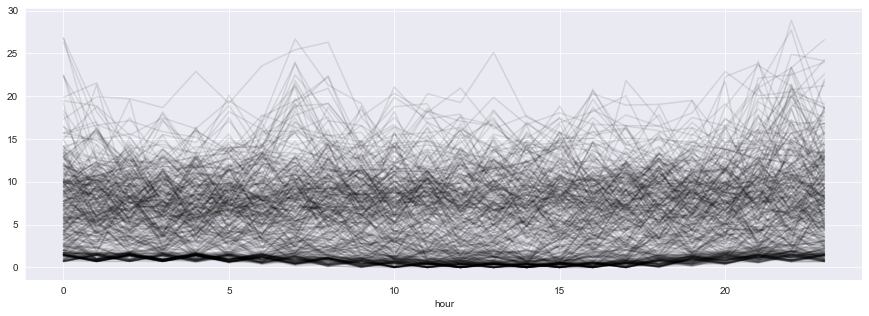

In [180]:
df_b1_pivot.plot(figsize=(15,5),color='black',alpha=0.1,legend=False)

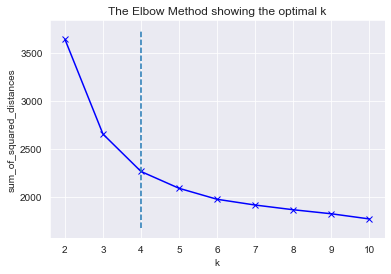

Optimal clustering number:4
----------------------------


In [181]:
df_PM_b1 = df_b1_pivot.copy()
df_PM_b1 = df_PM_b1.T

bestClusterNum_dept = Kmeans_bestClusterNum(df=df_PM_b1.fillna(0), range_min=2, range_max=10, max_iter=10000, n_jobs=-1)

In [182]:
def get_kmeans_results(data, max_clusters, metric='euclidean', seed=23):
    """
    Runs KMeans n times (according to max_cluster range)

    data: pd.DataFrame or np.array
        Time Series Data
    max_clusters: int
        Number of different clusters for KMeans algorithm
    metric: str
        Distance metric between the observations
    seed: int
        random seed
    Returns: 
    -------
    None      
    """
    # Main metrics
    distortions = []
    silhouette = []
    clusters_range = range(2, max_clusters+1)
    
    for K in tqdm(clusters_range):
        kmeans_model = TimeSeriesKMeans(n_clusters=K, metric=metric, n_jobs=-1, max_iter=10, random_state=seed)
        kmeans_model.fit(data)
        distortions.append(kmeans_model.inertia_)
        if K > 1:
            silhouette.append(silhouette_score(data, kmeans_model.labels_))
        
    # Visualization
    plt.figure(figsize=(10,4))
    plt.plot(clusters_range, distortions, 'bx-')
    plt.xlabel('k')
    plt.ylabel('Distortion')
    plt.title('Elbow Method')
    
    plt.figure(figsize=(10,4))
    plt.plot(clusters_range, silhouette, 'bx-')
    plt.xlabel('k')
    plt.ylabel('Silhouette score')
    plt.title('Silhouette');

In [183]:
#get_kmeans_results(data=df_PM_b1.fillna(0), max_clusters=10, metric='dtw', seed=23)

Cluster No.: 0
Amount of meters: 134


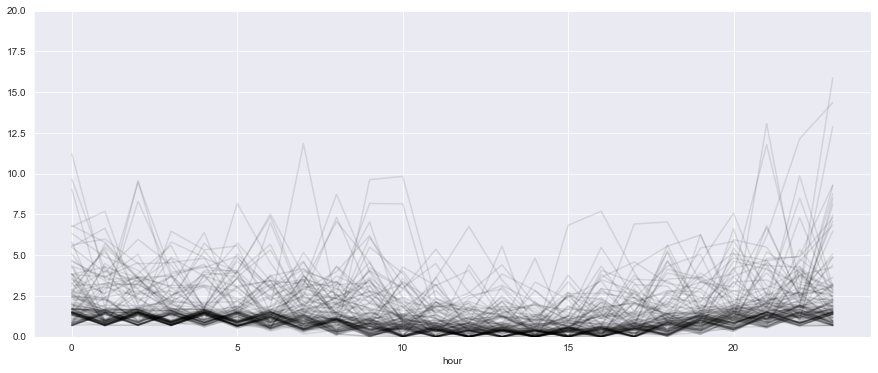

-----------------------------------------------------------------------------------
Cluster No.: 1
Amount of meters: 39


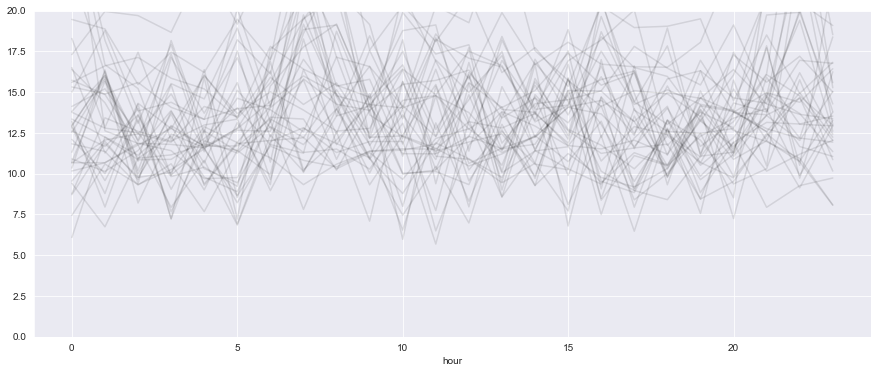

-----------------------------------------------------------------------------------
Cluster No.: 2
Amount of meters: 105


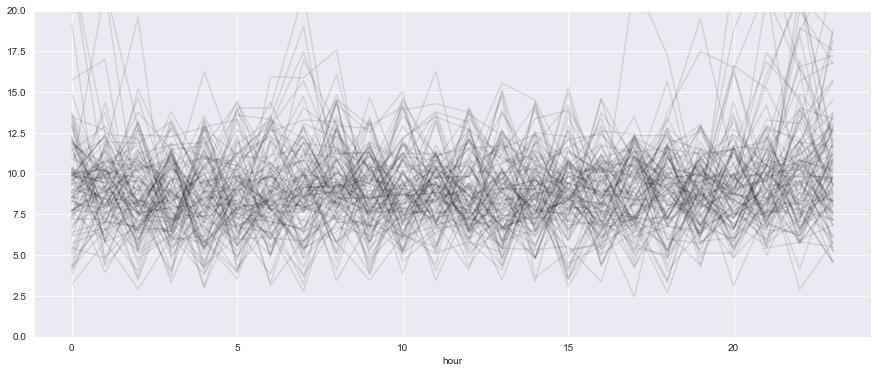

-----------------------------------------------------------------------------------
Cluster No.: 3
Amount of meters: 87


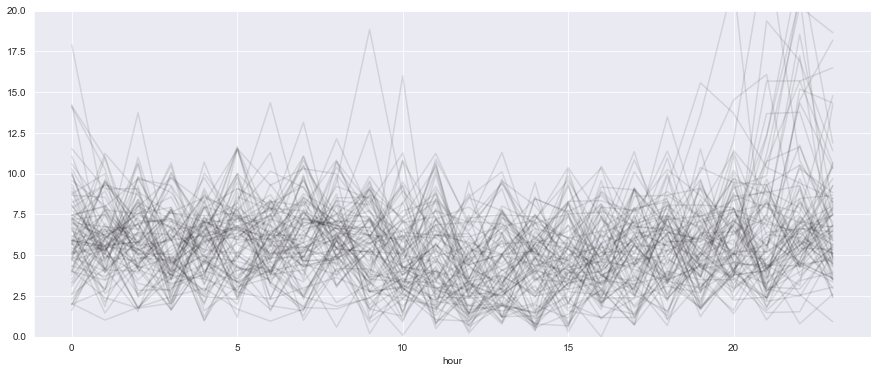

-----------------------------------------------------------------------------------


In [184]:
df_PM_b1['ClusterNo'] = Kmeans_clustering(df=df_PM_b1.fillna(0), clusterNum=4, max_iter=10000, n_jobs=-1)

for ClusterNo in df_PM_b1['ClusterNo'].sort_values().unique():
    df_plot = df_PM_b1[df_PM_b1['ClusterNo']==ClusterNo].T.drop('ClusterNo')
    print('Cluster No.: ' + str(ClusterNo))    
    print('Amount of meters: ' + str(len(df_plot.T)))
    df_plot.plot(figsize=(15,6),color='black',alpha=0.1,legend=False, ylim=(0, 20))
    plt.show()
    print('-----------------------------------------------------------------------------------')

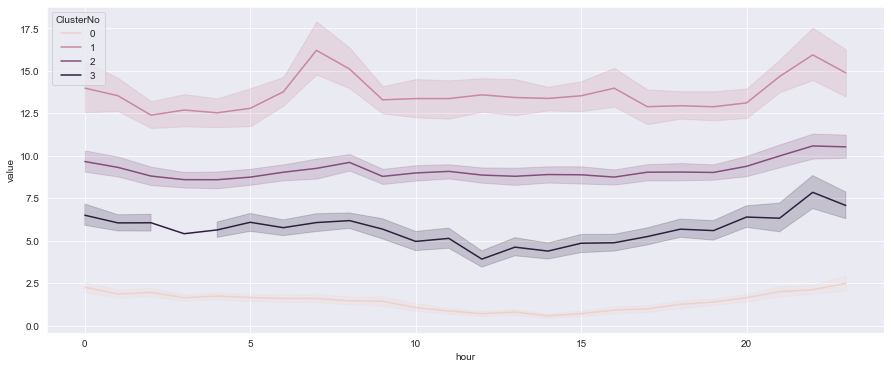

In [185]:
plt.figure(figsize=(15,6))
ax = sns.lineplot(x="hour", y="value", hue="ClusterNo",
                  data=df_PM_b1.melt(id_vars='ClusterNo'))

In [186]:
df= df_b1.merge(df_PM_b1.reset_index()[['date', 'ClusterNo']], on='date')

In [187]:
df.rename(columns = {'load':'b1','ClusterNo':'ClusterNob1'}, inplace = True)

In [188]:
df

,Date_Hour_start,b1,date,hour,ClusterNob1
0,2019-01-01 00:00:00,9.780,2019-01-01,0,2
1,2019-01-01 01:00:00,12.408,2019-01-01,1,2
2,2019-01-01 02:00:00,8.044,2019-01-01,2,2
3,2019-01-01 03:00:00,8.362,2019-01-01,3,2
4,2019-01-01 04:00:00,9.532,2019-01-01,4,2
...,...,...,...,...,...
8755,2019-12-31 19:00:00,9.984,2019-12-31,19,2
8756,2019-12-31 20:00:00,9.918,2019-12-31,20,2
8757,2019-12-31 21:00:00,9.934,2019-12-31,21,2
8758,2019-12-31 22:00:00,11.994,2019-12-31,22,2


### b2

In [189]:
df_community['b2'].iplot()

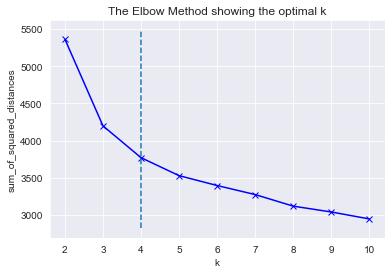

Optimal clustering number:4
----------------------------


In [190]:
df_b2 = pd.DataFrame({'Date_Hour_start': df_community['Date_Hour_start'],
        'load':  df_community['b2']})
df_b2['date'] = df_b2['Date_Hour_start'].dt.date    
df_b2['hour'] = df_b2['Date_Hour_start'].dt.hour
df_b2_pivot = df_b2.pivot_table(index='hour', columns='date')
df_PM_b2 = df_b2_pivot.copy()
df_PM_b2 = df_PM_b2.T

bestClusterNum_dept = Kmeans_bestClusterNum(df=df_PM_b2.fillna(0), range_min=2, range_max=10, max_iter=10000, n_jobs=-1)

Cluster No.: 0
Amount of meters: 151


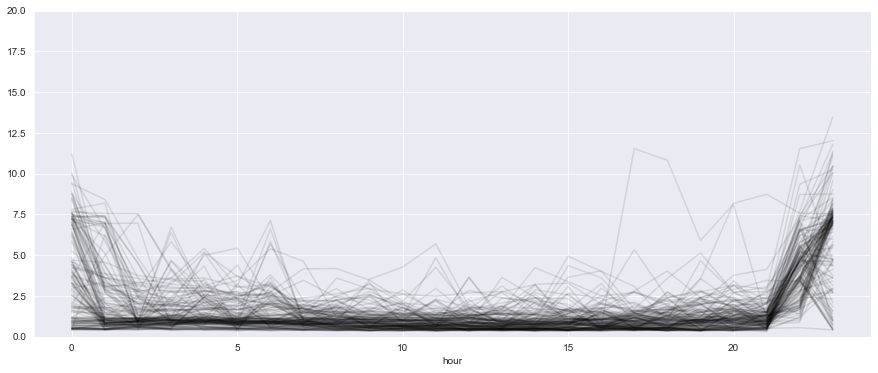

-----------------------------------------------------------------------------------
Cluster No.: 1
Amount of meters: 106


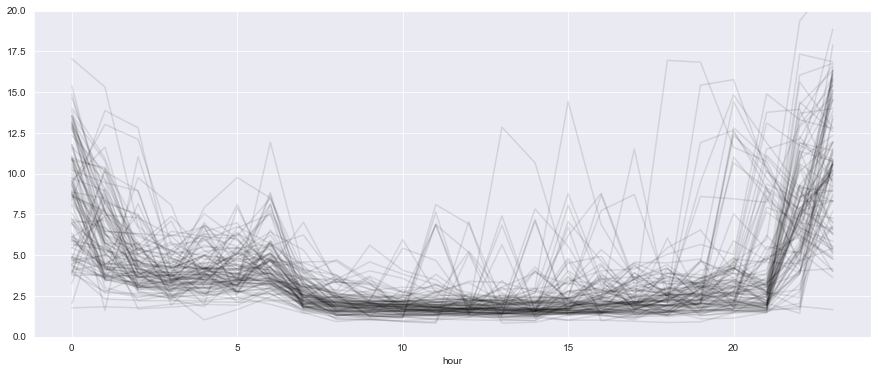

-----------------------------------------------------------------------------------
Cluster No.: 2
Amount of meters: 76


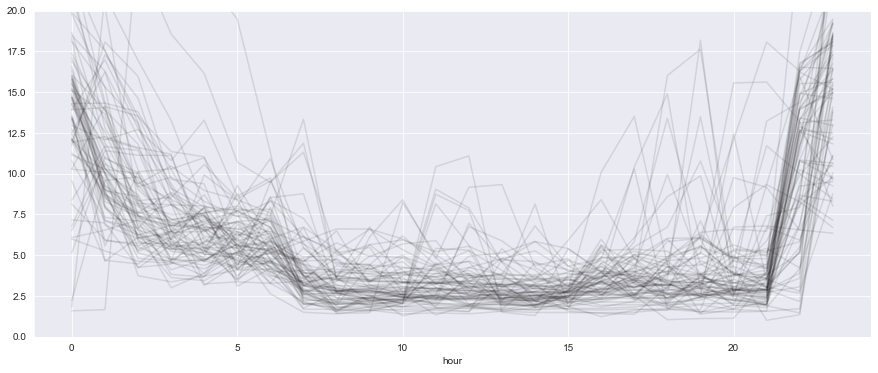

-----------------------------------------------------------------------------------
Cluster No.: 3
Amount of meters: 32


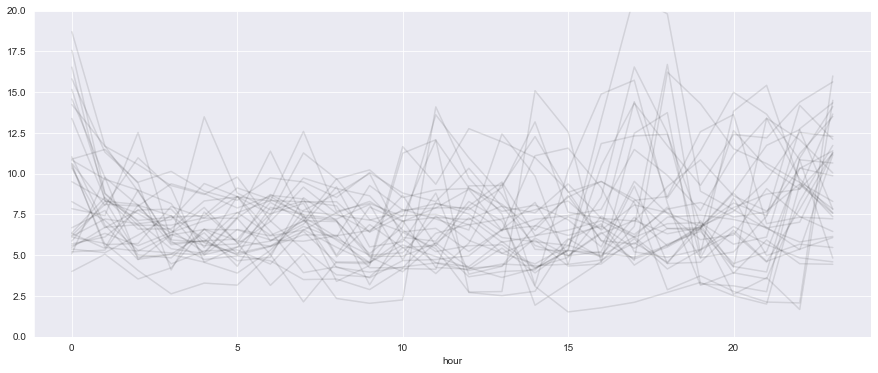

-----------------------------------------------------------------------------------


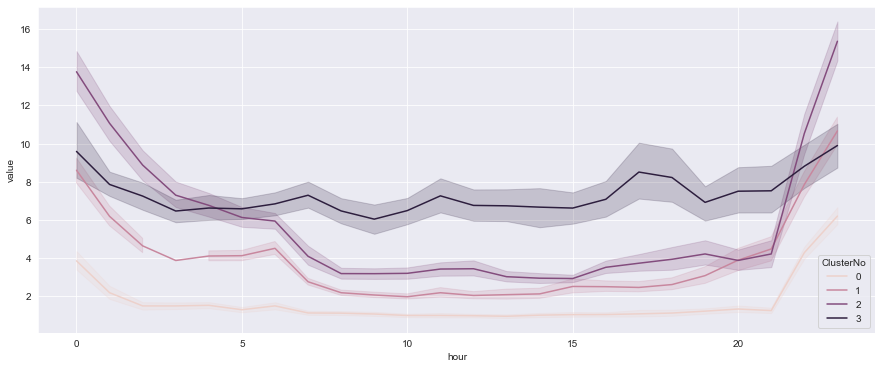

In [191]:
df_PM_b2['ClusterNo'] = Kmeans_clustering(df=df_PM_b2.fillna(0), clusterNum=4, max_iter=10000, n_jobs=-1)

for ClusterNo in df_PM_b2['ClusterNo'].sort_values().unique():
    df_plot = df_PM_b2[df_PM_b2['ClusterNo']==ClusterNo].T.drop('ClusterNo')
    print('Cluster No.: ' + str(ClusterNo))    
    print('Amount of meters: ' + str(len(df_plot.T)))
    df_plot.plot(figsize=(15,6),color='black',alpha=0.1,legend=False, ylim=(0, 20))
    plt.show()
    print('-----------------------------------------------------------------------------------')

plt.figure(figsize=(15,6))
ax = sns.lineplot(x="hour", y="value", hue="ClusterNo",
                  data=df_PM_b2.melt(id_vars='ClusterNo'))

In [192]:
df2= df_b2.merge(df_PM_b2.reset_index()[['date', 'ClusterNo']], on='date')
df['ClusterNob2'] = df2['ClusterNo']
df['b2'] = df2['load']

In [193]:
df

,Date_Hour_start,b1,date,hour,ClusterNob1,ClusterNob2,b2
0,2019-01-01 00:00:00,9.780,2019-01-01,0,2,2,14.698
1,2019-01-01 01:00:00,12.408,2019-01-01,1,2,2,10.672
2,2019-01-01 02:00:00,8.044,2019-01-01,2,2,2,7.426
3,2019-01-01 03:00:00,8.362,2019-01-01,3,2,2,6.542
4,2019-01-01 04:00:00,9.532,2019-01-01,4,2,2,8.716
...,...,...,...,...,...,...,...
8755,2019-12-31 19:00:00,9.984,2019-12-31,19,2,1,1.736
8756,2019-12-31 20:00:00,9.918,2019-12-31,20,2,1,1.586
8757,2019-12-31 21:00:00,9.934,2019-12-31,21,2,1,1.576
8758,2019-12-31 22:00:00,11.994,2019-12-31,22,2,1,1.866


## b3

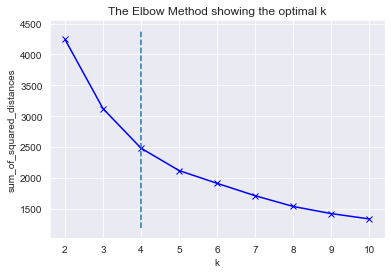

Optimal clustering number:4
----------------------------


In [194]:
df_b3 = pd.DataFrame({'Date_Hour_start': df_community['Date_Hour_start'],
        'load':  df_community['b3']})
df_b3['date'] = df_b3['Date_Hour_start'].dt.date    
df_b3['hour'] = df_b3['Date_Hour_start'].dt.hour
df_b3_pivot = df_b3.pivot_table(index='hour', columns='date')
df_PM_b3 = df_b3_pivot.copy()
df_PM_b3 = df_PM_b3.T

bestClusterNum_dept = Kmeans_bestClusterNum(df=df_PM_b3.fillna(0), range_min=2, range_max=10, max_iter=10000, n_jobs=-1)

In [195]:
df_PM_b3['ClusterNo'] = Kmeans_clustering(df=df_PM_b3.fillna(0), clusterNum=4, max_iter=10000, n_jobs=-1)
df3= df_b3.merge(df_PM_b3.reset_index()[['date', 'ClusterNo']], on='date')
df['ClusterNob3'] = df3['ClusterNo']
df['b3'] = df3['load']

In [196]:
df

,Date_Hour_start,b1,date,hour,ClusterNob1,ClusterNob2,b2,ClusterNob3,b3
0,2019-01-01 00:00:00,9.780,2019-01-01,0,2,2,14.698,1,7
1,2019-01-01 01:00:00,12.408,2019-01-01,1,2,2,10.672,1,6
2,2019-01-01 02:00:00,8.044,2019-01-01,2,2,2,7.426,1,7
3,2019-01-01 03:00:00,8.362,2019-01-01,3,2,2,6.542,1,7
4,2019-01-01 04:00:00,9.532,2019-01-01,4,2,2,8.716,1,7
...,...,...,...,...,...,...,...,...,...
8755,2019-12-31 19:00:00,9.984,2019-12-31,19,2,1,1.736,3,13
8756,2019-12-31 20:00:00,9.918,2019-12-31,20,2,1,1.586,3,11
8757,2019-12-31 21:00:00,9.934,2019-12-31,21,2,1,1.576,3,11
8758,2019-12-31 22:00:00,11.994,2019-12-31,22,2,1,1.866,3,11


## b4

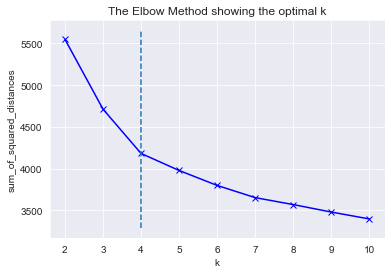

Optimal clustering number:4
----------------------------


In [197]:
df_b4 = pd.DataFrame({'Date_Hour_start': df_community['Date_Hour_start'],
        'load':  df_community['b4']})
df_b4['date'] = df_b4['Date_Hour_start'].dt.date    
df_b4['hour'] = df_b4['Date_Hour_start'].dt.hour
df_b4_pivot = df_b4.pivot_table(index='hour', columns='date')
df_PM_b4 = df_b4_pivot.copy()
df_PM_b4 = df_PM_b4.T

bestClusterNum_dept = Kmeans_bestClusterNum(df=df_PM_b4.fillna(0), range_min=2, range_max=10, max_iter=10000, n_jobs=-1)

In [198]:
df_PM_b4['ClusterNo'] = Kmeans_clustering(df=df_PM_b4.fillna(0), clusterNum=4, max_iter=10000, n_jobs=-1)
df4= df_b4.merge(df_PM_b4.reset_index()[['date', 'ClusterNo']], on='date')
df['ClusterNob4'] = df4['ClusterNo']
df['b4'] = df4['load']

In [199]:
df

,Date_Hour_start,b1,date,hour,ClusterNob1,ClusterNob2,b2,ClusterNob3,b3,ClusterNob4,b4
0,2019-01-01 00:00:00,9.780,2019-01-01,0,2,2,14.698,1,7,3,13.828
1,2019-01-01 01:00:00,12.408,2019-01-01,1,2,2,10.672,1,6,3,13.376
2,2019-01-01 02:00:00,8.044,2019-01-01,2,2,2,7.426,1,7,3,10.952
3,2019-01-01 03:00:00,8.362,2019-01-01,3,2,2,6.542,1,7,3,5.522
4,2019-01-01 04:00:00,9.532,2019-01-01,4,2,2,8.716,1,7,3,7.390
...,...,...,...,...,...,...,...,...,...,...,...
8755,2019-12-31 19:00:00,9.984,2019-12-31,19,2,1,1.736,3,13,1,3.748
8756,2019-12-31 20:00:00,9.918,2019-12-31,20,2,1,1.586,3,11,1,2.399
8757,2019-12-31 21:00:00,9.934,2019-12-31,21,2,1,1.576,3,11,1,2.173
8758,2019-12-31 22:00:00,11.994,2019-12-31,22,2,1,1.866,3,11,1,7.614


## b5

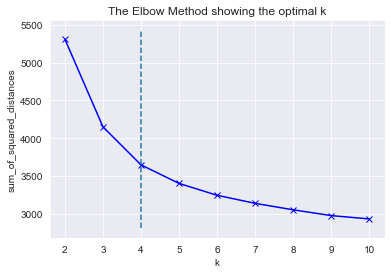

Optimal clustering number:4
----------------------------


In [200]:
df_b5 = pd.DataFrame({'Date_Hour_start': df_community['Date_Hour_start'],
        'load':  df_community['b5']})
df_b5['date'] = df_b5['Date_Hour_start'].dt.date    
df_b5['hour'] = df_b5['Date_Hour_start'].dt.hour
df_b5_pivot = df_b5.pivot_table(index='hour', columns='date')
df_PM_b5 = df_b5_pivot.copy()
df_PM_b5 = df_PM_b5.T

bestClusterNum_dept = Kmeans_bestClusterNum(df=df_PM_b5.fillna(0), range_min=2, range_max=10, max_iter=10000, n_jobs=-1)

In [201]:
df_PM_b5['ClusterNo'] = Kmeans_clustering(df=df_PM_b5.fillna(0), clusterNum=4, max_iter=10000, n_jobs=-1)
df5= df_b5.merge(df_PM_b5.reset_index()[['date', 'ClusterNo']], on='date')
df['ClusterNob5'] = df5['ClusterNo']
df['b5'] = df5['load']

In [202]:
df

,Date_Hour_start,b1,date,hour,ClusterNob1,ClusterNob2,b2,ClusterNob3,b3,ClusterNob4,b4,ClusterNob5,b5
0,2019-01-01 00:00:00,9.780,2019-01-01,0,2,2,14.698,1,7,3,13.828,3,20.277
1,2019-01-01 01:00:00,12.408,2019-01-01,1,2,2,10.672,1,6,3,13.376,3,17.127
2,2019-01-01 02:00:00,8.044,2019-01-01,2,2,2,7.426,1,7,3,10.952,3,12.719
3,2019-01-01 03:00:00,8.362,2019-01-01,3,2,2,6.542,1,7,3,5.522,3,8.057
4,2019-01-01 04:00:00,9.532,2019-01-01,4,2,2,8.716,1,7,3,7.390,3,10.193
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2019-12-31 19:00:00,9.984,2019-12-31,19,2,1,1.736,3,13,1,3.748,3,2.212
8756,2019-12-31 20:00:00,9.918,2019-12-31,20,2,1,1.586,3,11,1,2.399,3,1.591
8757,2019-12-31 21:00:00,9.934,2019-12-31,21,2,1,1.576,3,11,1,2.173,3,1.057
8758,2019-12-31 22:00:00,11.994,2019-12-31,22,2,1,1.866,3,11,1,7.614,3,6.027


## b6

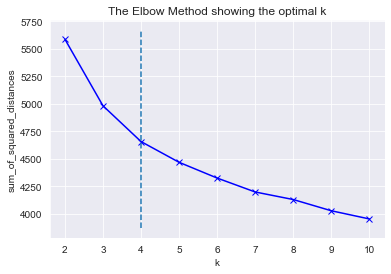

Optimal clustering number:4
----------------------------


In [203]:
df_b6 = pd.DataFrame({'Date_Hour_start': df_community['Date_Hour_start'],
        'load':  df_community['b6']})
df_b6['date'] = df_b6['Date_Hour_start'].dt.date    
df_b6['hour'] = df_b6['Date_Hour_start'].dt.hour
df_b6_pivot = df_b6.pivot_table(index='hour', columns='date')
df_PM_b6 = df_b6_pivot.copy()
df_PM_b6 = df_PM_b6.T

bestClusterNum_dept = Kmeans_bestClusterNum(df=df_PM_b6.fillna(0), range_min=2, range_max=10, max_iter=10000, n_jobs=-1)

In [204]:
df_PM_b6['ClusterNo'] = Kmeans_clustering(df=df_PM_b6.fillna(0), clusterNum=4, max_iter=10000, n_jobs=-1)
df6= df_b6.merge(df_PM_b6.reset_index()[['date', 'ClusterNo']], on='date')
df['ClusterNob6'] = df6['ClusterNo']
df['b6'] = df6['load']

In [205]:
df

,Date_Hour_start,b1,date,hour,ClusterNob1,ClusterNob2,b2,ClusterNob3,b3,ClusterNob4,b4,ClusterNob5,b5,ClusterNob6,b6
0,2019-01-01 00:00:00,9.780,2019-01-01,0,2,2,14.698,1,7,3,13.828,3,20.277,1,7.467
1,2019-01-01 01:00:00,12.408,2019-01-01,1,2,2,10.672,1,6,3,13.376,3,17.127,1,6.576
2,2019-01-01 02:00:00,8.044,2019-01-01,2,2,2,7.426,1,7,3,10.952,3,12.719,1,6.695
3,2019-01-01 03:00:00,8.362,2019-01-01,3,2,2,6.542,1,7,3,5.522,3,8.057,1,5.004
4,2019-01-01 04:00:00,9.532,2019-01-01,4,2,2,8.716,1,7,3,7.390,3,10.193,1,3.634
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2019-12-31 19:00:00,9.984,2019-12-31,19,2,1,1.736,3,13,1,3.748,3,2.212,1,13.404
8756,2019-12-31 20:00:00,9.918,2019-12-31,20,2,1,1.586,3,11,1,2.399,3,1.591,1,12.651
8757,2019-12-31 21:00:00,9.934,2019-12-31,21,2,1,1.576,3,11,1,2.173,3,1.057,1,8.558
8758,2019-12-31 22:00:00,11.994,2019-12-31,22,2,1,1.866,3,11,1,7.614,3,6.027,1,7.343


## b7

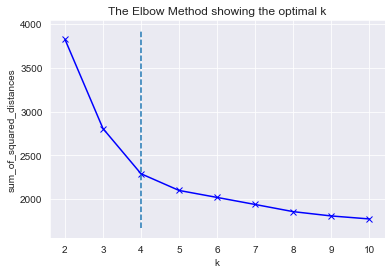

Optimal clustering number:4
----------------------------


In [206]:
df_b7 = pd.DataFrame({'Date_Hour_start': df_community['Date_Hour_start'],
        'load':  df_community['b7']})
df_b7['date'] = df_b7['Date_Hour_start'].dt.date    
df_b7['hour'] = df_b7['Date_Hour_start'].dt.hour
df_b7_pivot = df_b7.pivot_table(index='hour', columns='date')
df_PM_b7 = df_b7_pivot.copy()
df_PM_b7 = df_PM_b7.T

bestClusterNum_dept = Kmeans_bestClusterNum(df=df_PM_b7.fillna(0), range_min=2, range_max=10, max_iter=10000, n_jobs=-1)

In [207]:
df_PM_b7['ClusterNo'] = Kmeans_clustering(df=df_PM_b7.fillna(0), clusterNum=4, max_iter=10000, n_jobs=-1)
df7= df_b7.merge(df_PM_b7.reset_index()[['date', 'ClusterNo']], on='date')
df['ClusterNob7'] = df7['ClusterNo']
df['b7'] = df7['load']

In [208]:
df

,Date_Hour_start,b1,date,hour,ClusterNob1,ClusterNob2,b2,ClusterNob3,b3,ClusterNob4,b4,ClusterNob5,b5,ClusterNob6,b6,ClusterNob7,b7
0,2019-01-01 00:00:00,9.780,2019-01-01,0,2,2,14.698,1,7,3,13.828,3,20.277,1,7.467,3,19.588
1,2019-01-01 01:00:00,12.408,2019-01-01,1,2,2,10.672,1,6,3,13.376,3,17.127,1,6.576,3,16.876
2,2019-01-01 02:00:00,8.044,2019-01-01,2,2,2,7.426,1,7,3,10.952,3,12.719,1,6.695,3,11.448
3,2019-01-01 03:00:00,8.362,2019-01-01,3,2,2,6.542,1,7,3,5.522,3,8.057,1,5.004,3,10.723
4,2019-01-01 04:00:00,9.532,2019-01-01,4,2,2,8.716,1,7,3,7.390,3,10.193,1,3.634,3,13.482
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2019-12-31 19:00:00,9.984,2019-12-31,19,2,1,1.736,3,13,1,3.748,3,2.212,1,13.404,3,6.728
8756,2019-12-31 20:00:00,9.918,2019-12-31,20,2,1,1.586,3,11,1,2.399,3,1.591,1,12.651,3,6.545
8757,2019-12-31 21:00:00,9.934,2019-12-31,21,2,1,1.576,3,11,1,2.173,3,1.057,1,8.558,3,6.543
8758,2019-12-31 22:00:00,11.994,2019-12-31,22,2,1,1.866,3,11,1,7.614,3,6.027,1,7.343,3,7.863


## b8

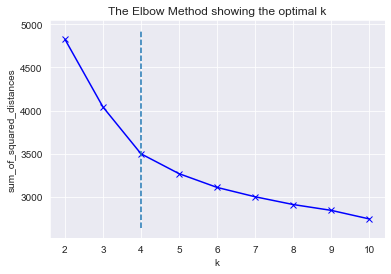

Optimal clustering number:4
----------------------------


In [209]:
df_b8 = pd.DataFrame({'Date_Hour_start': df_community['Date_Hour_start'],
        'load':  df_community['b8']})
df_b8['date'] = df_b8['Date_Hour_start'].dt.date    
df_b8['hour'] = df_b8['Date_Hour_start'].dt.hour
df_b8_pivot = df_b8.pivot_table(index='hour', columns='date')
df_PM_b8 = df_b8_pivot.copy()
df_PM_b8 = df_PM_b8.T

bestClusterNum_dept = Kmeans_bestClusterNum(df=df_PM_b8.fillna(0), range_min=2, range_max=10, max_iter=10000, n_jobs=-1)

In [210]:
df_PM_b8['ClusterNo'] = Kmeans_clustering(df=df_PM_b8.fillna(0), clusterNum=4, max_iter=10000, n_jobs=-1)
df8= df_b8.merge(df_PM_b8.reset_index()[['date', 'ClusterNo']], on='date')
df['ClusterNob8'] = df8['ClusterNo']
df['b8'] = df8['load']

In [211]:
df

,Date_Hour_start,b1,date,hour,ClusterNob1,ClusterNob2,b2,ClusterNob3,b3,ClusterNob4,b4,ClusterNob5,b5,ClusterNob6,b6,ClusterNob7,b7,ClusterNob8,b8
0,2019-01-01 00:00:00,9.780,2019-01-01,0,2,2,14.698,1,7,3,13.828,3,20.277,1,7.467,3,19.588,0,8.295
1,2019-01-01 01:00:00,12.408,2019-01-01,1,2,2,10.672,1,6,3,13.376,3,17.127,1,6.576,3,16.876,0,11.388
2,2019-01-01 02:00:00,8.044,2019-01-01,2,2,2,7.426,1,7,3,10.952,3,12.719,1,6.695,3,11.448,0,10.752
3,2019-01-01 03:00:00,8.362,2019-01-01,3,2,2,6.542,1,7,3,5.522,3,8.057,1,5.004,3,10.723,0,5.976
4,2019-01-01 04:00:00,9.532,2019-01-01,4,2,2,8.716,1,7,3,7.390,3,10.193,1,3.634,3,13.482,0,8.370
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2019-12-31 19:00:00,9.984,2019-12-31,19,2,1,1.736,3,13,1,3.748,3,2.212,1,13.404,3,6.728,0,21.867
8756,2019-12-31 20:00:00,9.918,2019-12-31,20,2,1,1.586,3,11,1,2.399,3,1.591,1,12.651,3,6.545,0,11.790
8757,2019-12-31 21:00:00,9.934,2019-12-31,21,2,1,1.576,3,11,1,2.173,3,1.057,1,8.558,3,6.543,0,12.504
8758,2019-12-31 22:00:00,11.994,2019-12-31,22,2,1,1.866,3,11,1,7.614,3,6.027,1,7.343,3,7.863,0,16.629


## b9

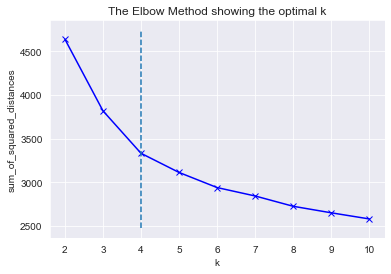

Optimal clustering number:4
----------------------------


In [212]:
df_b9 = pd.DataFrame({'Date_Hour_start': df_community['Date_Hour_start'],
        'load':  df_community['b9']})
df_b9['date'] = df_b9['Date_Hour_start'].dt.date    
df_b9['hour'] = df_b9['Date_Hour_start'].dt.hour
df_b9_pivot = df_b9.pivot_table(index='hour', columns='date')
df_PM_b9 = df_b9_pivot.copy()
df_PM_b9 = df_PM_b9.T

bestClusterNum_dept = Kmeans_bestClusterNum(df=df_PM_b9.fillna(0), range_min=2, range_max=10, max_iter=10000, n_jobs=-1)

In [213]:
df_PM_b9['ClusterNo'] = Kmeans_clustering(df=df_PM_b9.fillna(0), clusterNum=4, max_iter=10000, n_jobs=-1)
df9= df_b9.merge(df_PM_b9.reset_index()[['date', 'ClusterNo']], on='date')
df['ClusterNob9'] = df9['ClusterNo']
df['b9'] = df9['load']

In [214]:
df

,Date_Hour_start,b1,date,hour,ClusterNob1,ClusterNob2,b2,ClusterNob3,b3,ClusterNob4,...,ClusterNob5,b5,ClusterNob6,b6,ClusterNob7,b7,ClusterNob8,b8,ClusterNob9,b9
0,2019-01-01 00:00:00,9.780,2019-01-01,0,2,2,14.698,1,7,3,...,3,20.277,1,7.467,3,19.588,0,8.295,1,4.319
1,2019-01-01 01:00:00,12.408,2019-01-01,1,2,2,10.672,1,6,3,...,3,17.127,1,6.576,3,16.876,0,11.388,1,6.452
2,2019-01-01 02:00:00,8.044,2019-01-01,2,2,2,7.426,1,7,3,...,3,12.719,1,6.695,3,11.448,0,10.752,1,7.021
3,2019-01-01 03:00:00,8.362,2019-01-01,3,2,2,6.542,1,7,3,...,3,8.057,1,5.004,3,10.723,0,5.976,1,5.062
4,2019-01-01 04:00:00,9.532,2019-01-01,4,2,2,8.716,1,7,3,...,3,10.193,1,3.634,3,13.482,0,8.370,1,6.648
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2019-12-31 19:00:00,9.984,2019-12-31,19,2,1,1.736,3,13,1,...,3,2.212,1,13.404,3,6.728,0,21.867,1,10.791
8756,2019-12-31 20:00:00,9.918,2019-12-31,20,2,1,1.586,3,11,1,...,3,1.591,1,12.651,3,6.545,0,11.790,1,6.297
8757,2019-12-31 21:00:00,9.934,2019-12-31,21,2,1,1.576,3,11,1,...,3,1.057,1,8.558,3,6.543,0,12.504,1,6.743
8758,2019-12-31 22:00:00,11.994,2019-12-31,22,2,1,1.866,3,11,1,...,3,6.027,1,7.343,3,7.863,0,16.629,1,9.268


## b10

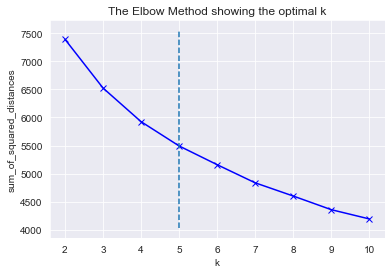

Optimal clustering number:5
----------------------------


In [215]:
df_b10 = pd.DataFrame({'Date_Hour_start': df_community['Date_Hour_start'],
        'load':  df_community['b10']})
df_b10['date'] = df_b10['Date_Hour_start'].dt.date    
df_b10['hour'] = df_b10['Date_Hour_start'].dt.hour
df_b10_pivot = df_b10.pivot_table(index='hour', columns='date')
df_PM_b10 = df_b10_pivot.copy()
df_PM_b10 = df_PM_b10.T

bestClusterNum_dept = Kmeans_bestClusterNum(df=df_PM_b10.fillna(0), range_min=2, range_max=10, max_iter=10000, n_jobs=-1)

In [216]:
df_PM_b10['ClusterNo'] = Kmeans_clustering(df=df_PM_b10.fillna(0), clusterNum=5, max_iter=10000, n_jobs=-1)
df10= df_b10.merge(df_PM_b10.reset_index()[['date', 'ClusterNo']], on='date')
df['ClusterNob10'] = df10['ClusterNo']
df['b10'] = df10['load']

In [217]:
df_scenario = df[['ClusterNob1', 'ClusterNob2','ClusterNob3',
'ClusterNob4','ClusterNob5','ClusterNob6','ClusterNob7',
'ClusterNob8','ClusterNob9','ClusterNob10']].value_counts().reset_index(name='count')
df_scenario['count'] = df_scenario['count']/24


In [218]:
df_scenario

,ClusterNob1,ClusterNob2,ClusterNob3,ClusterNob4,ClusterNob5,ClusterNob6,ClusterNob7,ClusterNob8,ClusterNob9,ClusterNob10,count
0,0,0,1,2,0,2,2,1,0,0,29.0
1,0,0,1,2,0,2,2,1,0,3,22.0
2,3,1,0,1,3,0,0,2,2,3,10.0
3,0,0,3,2,0,2,2,1,0,0,9.0
4,0,0,0,2,0,2,2,1,0,3,9.0
...,...,...,...,...,...,...,...,...,...,...,...
187,2,1,2,1,3,1,3,0,1,3,1.0
188,2,1,2,1,3,1,3,2,2,2,1.0
189,2,1,2,3,2,3,3,0,1,2,1.0
190,2,1,2,3,3,0,0,2,2,3,1.0


In [219]:
selected_scenario = df_scenario[df_scenario['count'] >= 9]

In [220]:
selected_scenario

,ClusterNob1,ClusterNob2,ClusterNob3,ClusterNob4,ClusterNob5,ClusterNob6,ClusterNob7,ClusterNob8,ClusterNob9,ClusterNob10,count
0,0,0,1,2,0,2,2,1,0,0,29.0
1,0,0,1,2,0,2,2,1,0,3,22.0
2,3,1,0,1,3,0,0,2,2,3,10.0
3,0,0,3,2,0,2,2,1,0,0,9.0
4,0,0,0,2,0,2,2,1,0,3,9.0


In [221]:
clusters = selected_scenario.drop(['count'], axis=1)

In [222]:
df

,Date_Hour_start,b1,date,hour,ClusterNob1,ClusterNob2,b2,ClusterNob3,b3,ClusterNob4,...,ClusterNob6,b6,ClusterNob7,b7,ClusterNob8,b8,ClusterNob9,b9,ClusterNob10,b10
0,2019-01-01 00:00:00,9.780,2019-01-01,0,2,2,14.698,1,7,3,...,1,7.467,3,19.588,0,8.295,1,4.319,3,6.0
1,2019-01-01 01:00:00,12.408,2019-01-01,1,2,2,10.672,1,6,3,...,1,6.576,3,16.876,0,11.388,1,6.452,3,4.5
2,2019-01-01 02:00:00,8.044,2019-01-01,2,2,2,7.426,1,7,3,...,1,6.695,3,11.448,0,10.752,1,7.021,3,6.0
3,2019-01-01 03:00:00,8.362,2019-01-01,3,2,2,6.542,1,7,3,...,1,5.004,3,10.723,0,5.976,1,5.062,3,6.0
4,2019-01-01 04:00:00,9.532,2019-01-01,4,2,2,8.716,1,7,3,...,1,3.634,3,13.482,0,8.370,1,6.648,3,6.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2019-12-31 19:00:00,9.984,2019-12-31,19,2,1,1.736,3,13,1,...,1,13.404,3,6.728,0,21.867,1,10.791,2,58.5
8756,2019-12-31 20:00:00,9.918,2019-12-31,20,2,1,1.586,3,11,1,...,1,12.651,3,6.545,0,11.790,1,6.297,2,55.5
8757,2019-12-31 21:00:00,9.934,2019-12-31,21,2,1,1.576,3,11,1,...,1,8.558,3,6.543,0,12.504,1,6.743,2,42.0
8758,2019-12-31 22:00:00,11.994,2019-12-31,22,2,1,1.866,3,11,1,...,1,7.343,3,7.863,0,16.629,1,9.268,2,19.5


In [223]:
import matplotlib.pyplot as plt

In [224]:
df['Sum'] = df[['b1', 'b2','b3',
'b4','b5','b6','b7',
'b8','b9','b10']].sum(axis=1)

In [225]:
df['daynu'] = df['Date_Hour_start'].dt.dayofyear - 1

In [226]:
def scenario_parameter(scenario_number):
   s=[]
   h = df[clusters.columns.values].values==clusters.iloc[scenario_number,:].values
   for i in range(len(h)):
      if h[i].all() == True:
         s.append(i)
   return(s)

In [227]:
def max_load(scenario_number):
    return(df[df['Sum']== max(df.iloc[scenario_parameter(scenario_number),:]['Sum'])])

In [228]:
def min_load(scenario_number):
    return(df[df['Sum']== min(df.iloc[scenario_parameter(scenario_number),:]['Sum'])])

In [229]:
day_list1 = []
for i in range(len(clusters)):
    day_list1.append(list(max_load(i)['daynu']))
for i in range(len(clusters)):
    day_list1.append(list(min_load(i)['daynu']))
    

In [230]:
day_list1

[[218], [156], [76], [192], [114], [208], [172], [125], [199], [141]]

In [231]:
day_list = sum(day_list1, [])
day_list = list(set(day_list))
day_list

[192, 199, 76, 172, 141, 208, 114, 218, 156, 125]

In [232]:
len(day_list)

10

In [233]:
day_df = df[df['daynu'].isin(day_list)]
day_df

,Date_Hour_start,b1,date,hour,ClusterNob1,ClusterNob2,b2,ClusterNob3,b3,ClusterNob4,...,ClusterNob7,b7,ClusterNob8,b8,ClusterNob9,b9,ClusterNob10,b10,Sum,daynu
1824,2019-03-18 00:00:00,5.700,2019-03-18,0,3,1,8.692,0,11,1,...,0,11.542,2,13.116,2,7.319,3,6.0,94.360,76
1825,2019-03-18 01:00:00,9.514,2019-03-18,1,3,1,7.626,0,10,1,...,0,12.383,2,5.043,2,3.426,3,7.5,79.803,76
1826,2019-03-18 02:00:00,6.568,2019-03-18,2,3,1,6.152,0,10,1,...,0,9.436,2,6.492,2,4.647,3,6.0,67.170,76
1827,2019-03-18 03:00:00,10.490,2019-03-18,3,3,1,5.316,0,11,1,...,0,10.561,2,8.175,2,5.635,3,6.0,68.934,76
1828,2019-03-18 04:00:00,3.230,2019-03-18,4,3,1,4.050,0,10,1,...,0,5.665,2,7.191,2,5.100,3,6.0,58.359,76
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5251,2019-08-07 19:00:00,0.526,2019-08-07,19,0,0,1.040,1,9,2,...,2,1.303,1,3.921,0,1.838,0,57.0,83.994,218
5252,2019-08-07 20:00:00,1.712,2019-08-07,20,0,0,0.500,1,6,2,...,2,1.356,1,1.911,0,1.008,0,42.0,72.440,218
5253,2019-08-07 21:00:00,1.902,2019-08-07,21,0,0,0.586,1,6,2,...,2,1.537,1,6.651,0,3.293,0,12.0,52.198,218
5254,2019-08-07 22:00:00,4.624,2019-08-07,22,0,0,3.546,1,8,2,...,2,5.858,1,12.186,0,7.083,0,12.0,69.566,218


In [234]:
day_df = day_df.reset_index(drop=True)

In [235]:
day_df.to_csv("scenario_s1.csv")

In [236]:
j = df[clusters.columns.values].values==clusters.iloc[0,:].values
ss = []
for i in range(len(j)):
    if j[i].all() == True:
        ss.append(i)

In [237]:
scenario_s2 = df.iloc[ss,:].reset_index(drop=True)

In [238]:
scenario_s2

,Date_Hour_start,b1,date,hour,ClusterNob1,ClusterNob2,b2,ClusterNob3,b3,ClusterNob4,...,ClusterNob7,b7,ClusterNob8,b8,ClusterNob9,b9,ClusterNob10,b10,Sum,daynu
0,2019-05-18 00:00:00,4.252,2019-05-18,0,0,0,7.610,1,9,2,...,2,9.736,1,2.406,0,1.552,0,7.5,49.787,137
1,2019-05-18 01:00:00,0.870,2019-05-18,1,0,0,1.718,1,10,2,...,2,2.153,1,3.228,0,2.117,0,9.0,36.406,137
2,2019-05-18 02:00:00,3.302,2019-05-18,2,0,0,0.990,1,9,2,...,2,2.641,1,3.888,0,2.437,0,6.0,34.821,137
3,2019-05-18 03:00:00,4.814,2019-05-18,3,0,0,1.090,1,9,2,...,2,3.497,1,3.447,0,2.353,0,9.0,38.032,137
4,2019-05-18 04:00:00,1.772,2019-05-18,4,0,0,0.980,1,7,2,...,2,1.866,1,2.391,0,1.508,0,7.5,28.005,137
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
691,2019-08-10 19:00:00,0.424,2019-08-10,19,0,0,0.374,1,5,2,...,2,0.586,1,2.583,0,4.040,0,58.5,76.689,221
692,2019-08-10 20:00:00,1.190,2019-08-10,20,0,0,0.548,1,5,2,...,2,1.143,1,2.472,0,1.941,0,42.0,60.037,221
693,2019-08-10 21:00:00,0.824,2019-08-10,21,0,0,0.720,1,5,2,...,2,1.132,1,4.047,0,2.629,0,16.5,37.769,221
694,2019-08-10 22:00:00,1.468,2019-08-10,22,0,0,4.716,1,7,2,...,2,5.450,1,3.396,0,2.375,0,9.0,43.563,221


In [239]:
scenario_s2.to_csv("scenario_s2.csv")

In [240]:
df.set_index('Date_Hour_start', inplace=True)

In [241]:
hourly_mean = df.groupby(df.index.hour).mean()

In [242]:
hourly_mean

,b1,hour,ClusterNob1,ClusterNob2,b2,ClusterNob3,b3,ClusterNob4,b4,ClusterNob5,...,ClusterNob7,b7,ClusterNob8,b8,ClusterNob9,b9,ClusterNob10,b10,Sum,daynu
Date_Hour_start,,,,,,,,,,,,,,,,,,,,,
0,6.660795,0.0,1.397260,0.969863,7.793715,1.356164,11.594521,1.884932,8.031647,1.484932,...,1.728767,11.124112,1.205479,8.330153,1.035616,5.031526,1.936986,7.076712,80.433268,182.000000
1,6.259638,1.0,1.397260,0.969863,5.684756,1.356164,11.709589,1.884932,6.082238,1.484932,...,1.728767,8.814575,1.205479,8.074627,1.035616,5.013416,1.936986,6.789041,70.198438,182.000000
2,6.027443,2.0,1.401639,0.969945,4.438694,1.355191,11.683060,1.882514,4.758530,1.489071,...,1.724044,7.452415,1.207650,8.329648,1.038251,5.216801,1.937158,6.614754,64.227161,181.745902
3,5.731027,3.0,1.392857,0.969780,3.817440,1.357143,11.585165,1.887363,6.675618,1.480769,...,1.733516,6.682953,1.203297,8.756679,1.032967,5.568967,1.936813,6.539835,66.415835,182.255495
4,5.801249,4.0,1.397260,0.969863,3.801814,1.356164,11.221918,1.884932,5.432773,1.484932,...,1.728767,6.702438,1.205479,9.020310,1.035616,5.769888,1.936986,6.575342,63.883989,182.000000
5,5.948904,5.0,1.397260,0.969863,3.574668,1.356164,13.673973,1.884932,3.926093,1.484932,...,1.728767,6.549121,1.205479,9.397134,1.035616,5.997263,1.936986,6.620548,63.277005,182.000000
6,6.041123,6.0,1.397260,0.969863,3.754104,1.356164,18.342466,1.884932,4.317827,1.484932,...,1.728767,6.774666,1.205479,10.255266,1.035616,6.430912,1.936986,7.261644,71.275616,182.000000
7,6.438515,7.0,1.397260,0.969863,2.745671,1.356164,26.715068,1.884932,3.046249,1.484932,...,1.728767,5.964929,1.205479,9.894460,1.035616,6.133373,1.936986,9.106849,76.708107,182.000000
8,6.398060,8.0,1.397260,0.969863,2.313096,1.356164,35.901370,1.884932,2.619545,1.484932,...,1.728767,5.512126,1.205479,9.191942,1.035616,5.647553,1.936986,11.169863,85.136600,182.000000


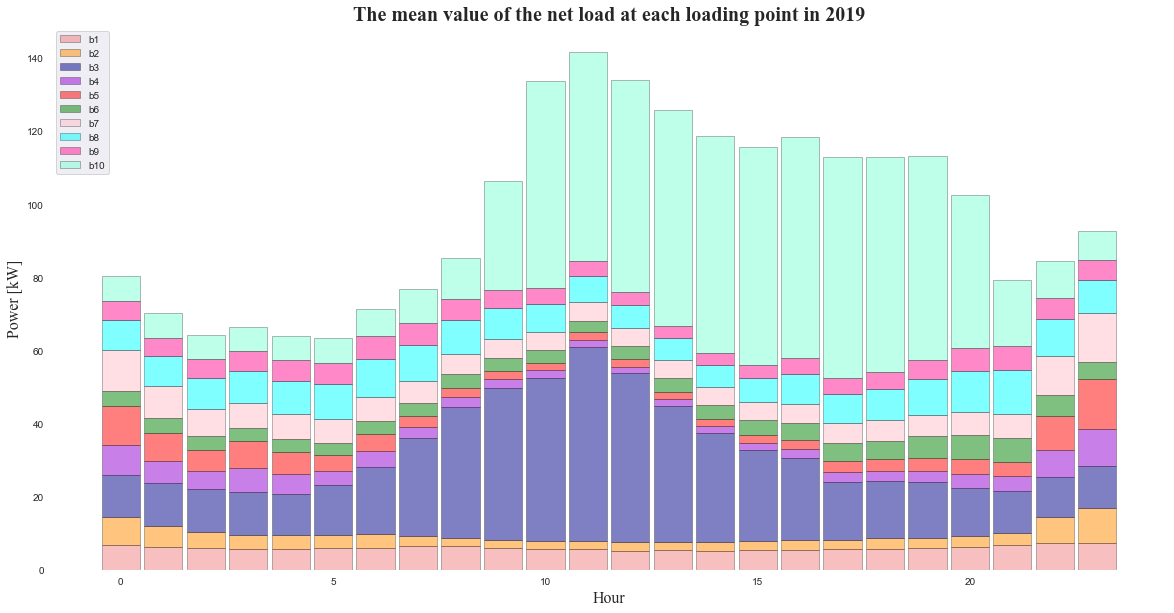

In [243]:
x_axis = hourly_mean.hour.to_numpy()
fig, ax1 = plt.subplots(figsize=(20, 10))
#ax2 = ax1.twinx()
ax1.set_facecolor("white")
ax1.bar(x_axis, hourly_mean['b1'], color='lightcoral', label='b1', alpha=0.5, width=0.9, edgecolor='k', linewidth=0.55)
ax1.bar(x_axis, hourly_mean['b2'], bottom=hourly_mean['b1'], color='darkorange', label='b2', alpha=0.5, width=0.9, edgecolor='k', linewidth=0.55)
ax1.bar(x_axis, hourly_mean['b3'], bottom=hourly_mean['b1']+ hourly_mean['b2'], color='darkblue', label='b3', alpha=0.5, width=0.9, edgecolor='k', linewidth=0.55)
ax1.bar(x_axis, hourly_mean['b4'], bottom=hourly_mean['b1']+hourly_mean['b2']+hourly_mean['b3'],color='darkviolet', label='b4', alpha=0.5, width=0.9, edgecolor='k', linewidth=0.55)
ax1.bar(x_axis, hourly_mean['b5'], bottom=hourly_mean['b1']+hourly_mean['b2']+hourly_mean['b3']+hourly_mean['b4'],color='red', label='b5', alpha=0.5, width=0.9, edgecolor='k', linewidth=0.55)
ax1.bar(x_axis, hourly_mean['b6'], bottom=hourly_mean['b1']+hourly_mean['b2']+hourly_mean['b3']+hourly_mean['b4']+hourly_mean['b5'],color='green', label='b6', alpha=0.5, width=0.9, edgecolor='k', linewidth=0.55)
ax1.bar(x_axis, hourly_mean['b7'], bottom=hourly_mean['b1']+hourly_mean['b2']+hourly_mean['b3']+hourly_mean['b4']+hourly_mean['b5']+hourly_mean['b6'],color='pink', label='b7', alpha=0.5, width=0.9, edgecolor='k', linewidth=0.55)
ax1.bar(x_axis, hourly_mean['b8'],  bottom=hourly_mean['b1']+hourly_mean['b2']+hourly_mean['b3']+hourly_mean['b4']+hourly_mean['b5']+hourly_mean['b6']+hourly_mean['b7'],color='cyan', label='b8', alpha=0.5, width=0.9, edgecolor='k', linewidth=0.55)
ax1.bar(x_axis, hourly_mean['b9'], bottom=hourly_mean['b1']+hourly_mean['b2']+hourly_mean['b3']+hourly_mean['b4']+hourly_mean['b5']+hourly_mean['b6']+hourly_mean['b7']+hourly_mean['b8'],color='deeppink', label='b9', alpha=0.5, width=0.9, edgecolor='k', linewidth=0.55)
ax1.bar(x_axis, hourly_mean['b10'], bottom=hourly_mean['b1']+hourly_mean['b2']+hourly_mean['b3']+hourly_mean['b4']+hourly_mean['b5']+hourly_mean['b6']+hourly_mean['b7']+hourly_mean['b8']+hourly_mean['b9'],color='aquamarine', label='b10', alpha=0.5, width=0.9, edgecolor='k', linewidth=0.55)
#ax = plt.gca()
ax1.set_title('The mean value of the net load at each loading point in 2019', fontname='Times New Roman', fontsize=20, fontweight="bold")
ax1.set_xlabel('Hour',fontsize=16, fontname='Times New Roman')
ax1.set_ylabel('Power [kW]',fontsize=16, fontname='Times New Roman')
#ax2.set_ylabel('Power (b7) [kW]',fontsize=16, fontname='Times New Roman')
#ax2.spines['right'].set_color('black')
#ax1.spines['left'].set_color('brown')
#ax1.spines['bottom'].set_color('midnightblue')
ax1.legend(loc='upper left')
#ax2.legend(loc='upper right')

plt.grid(linestyle='--', linewidth=0.5)
plt.savefig('netload.png', dpi=300)
plt.show()
